# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

**Line Chart.** Changes over time should be plotted using a line graph. By dividing each continent into its 1970 size (1970 = 100), all continents start from the same point, making their growth rates comparable despite the fact that Asia is significantly larger. Africa is represented in orange, and all other continents in grey for reference purposes. There are no gridlines or legends; labels appear at the end of each line.
**Conclusion:** Africa increased by about 3.9× (index 390), whereas Europe increased by only 13% (index 113).

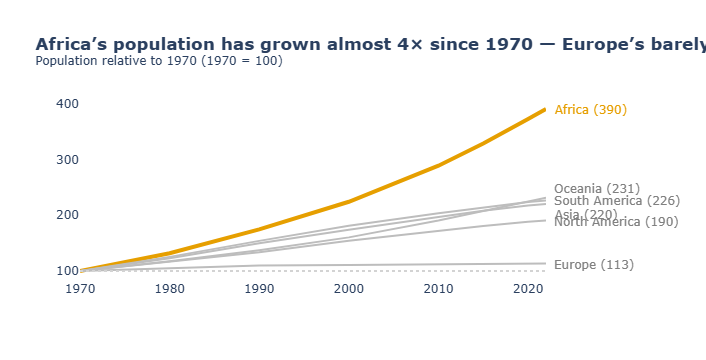

In [3]:
# Q1

GREY, ACCENT, BLUE = '#BDBDBD', '#E69F00', '#0072B2'   # CVD-safe (Okabe-Ito)

cont = df_long.groupby(['Continent', 'Year'], as_index=False)['Population'].sum()
base = cont[cont['Year'] == 1970].set_index('Continent')['Population']
cont['Index'] = cont['Population'] / cont['Continent'].map(base) * 100

colors = {c: GREY for c in cont['Continent'].unique()}
colors['Africa'] = ACCENT

fig = px.line(cont, x='Year', y='Index', color='Continent',
              color_discrete_map=colors, template='plotly_white',
              title='<b>Africa’s population has grown almost 4× since 1970 — Europe’s barely moved</b>'
                    '<br><sup>Population relative to 1970 (1970 = 100)</sup>')
fig.update_traces(line_width=2)
fig.update_traces(selector=dict(name='Africa'), line_width=4)

last = cont[cont['Year'] == 2022]
shift = {'Oceania': 10, 'South America': 0, 'Asia': -10}   # avoid overlapping labels
for _, r in last.iterrows():
    fig.add_annotation(x=2022, y=r['Index'], yshift=shift.get(r['Continent'], 0),
                       text=f"{r['Continent']} ({r['Index']:.0f})",
                       showarrow=False, xanchor='left', xshift=6,
                       font=dict(color=ACCENT if r['Continent'] == 'Africa' else 'grey'))
fig.add_hline(y=100, line_dash='dot', line_color='lightgrey')
fig.update_layout(showlegend=False, margin=dict(r=160))
fig.update_xaxes(title=None, showgrid=False, range=[1970, 2022])
fig.update_yaxes(title=None, showgrid=False)
fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

**Sorted horizontal bar graph.** This is a comparison of one figure among 15 named countries. The sorting of the bars makes the rank evident, while the horizontal bars help in maintaining readability of the country names. Only Africa is colored (orange), and hence the “how many in Africa” question can easily be answered. Numbers are shown on the bars, and hence the x-axis is omitted.
**Finding:** India (+860M) and China (+603M) dominate. Four of the top 15 belong to Africa: Nigeria, Ethiopia, DRC, and Egypt.

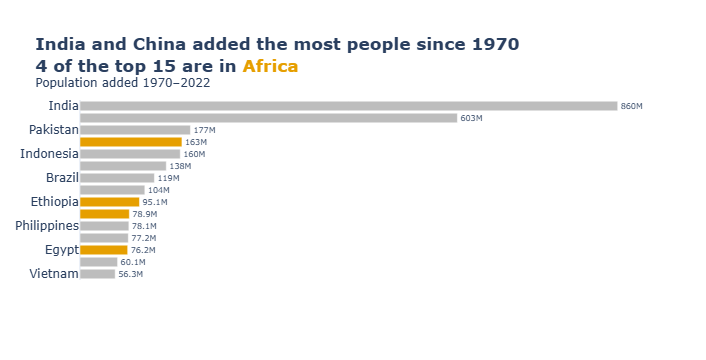

In [4]:
# Q2

df['Added'] = df['2022 Population'] - df['1970 Population']
top15 = df.nlargest(15, 'Added').sort_values('Added')
top15['Group'] = np.where(top15['Continent'] == 'Africa', 'Africa', 'Other continents')
n_africa = (top15['Continent'] == 'Africa').sum()

fig = px.bar(top15, x='Added', y='Country', orientation='h', color='Group',
             color_discrete_map={'Africa': ACCENT, 'Other continents': GREY},
             template='plotly_white',
             title=f'<b>India and China added the most people since 1970<br>'
                   f'{n_africa} of the top 15 are in <span style="color:{ACCENT}">Africa</span></b>'
                   '<br><sup>Population added 1970–2022</sup>')
fig.update_traces(texttemplate='%{x:.3s}', textposition='outside', cliponaxis=False)
fig.update_layout(showlegend=False, margin=dict(r=60))
fig.update_xaxes(title=None, showgrid=False, showticklabels=False)
fig.update_yaxes(title=None, categoryorder='total ascending')
fig.show()

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

**Scatterplot** - This is the relationship between two numeric values. They both cover many orders of magnitude (from 1 km² to 17M km²), which is why they are both on log scales. Otherwise, all the countries would bunch up in the top left corner. The colour depicts the continents using a CVD-friendly Okabe-Ito palette, and only the outliers are labeled.  
**Insight:** There is a positive correlation here (log-log correlation of ≈0.87) and it seems to be the same across all continents. Bangladesh and Singapore have significantly more people than would be expected from their land size.

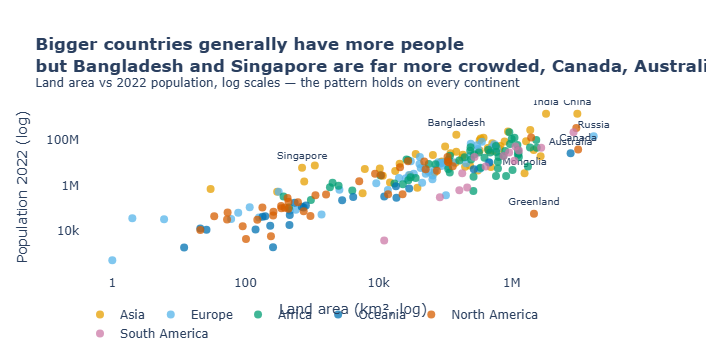

In [5]:
# Q3

outliers = ['Bangladesh', 'Singapore', 'India', 'China', 'Russia', 'Canada',
            'Australia', 'Mongolia', 'Greenland']
df['Label'] = np.where(df['Country'].isin(outliers), df['Country'], '')
okabe = ['#E69F00', '#56B4E9', '#009E73', '#0072B2', '#D55E00', '#CC79A7']

fig = px.scatter(df, x='Area', y='2022 Population', color='Continent', text='Label',
                 log_x=True, log_y=True, hover_name='Country',
                 color_discrete_sequence=okabe, template='plotly_white',
                 title='<b>Bigger countries generally have more people<br>but Bangladesh and Singapore are '
                       'far more crowded, Canada, Australia and Mongolia far emptier</b>'
                       '<br><sup>Land area vs 2022 population, log scales — the pattern holds on every continent</sup>')
fig.update_traces(textposition='top center', marker=dict(size=8, opacity=0.75), textfont_size=10)
fig.update_layout(legend=dict(title=None, orientation='h', y=-0.15))
fig.update_xaxes(title='Land area (km², log)', showgrid=False)
fig.update_yaxes(title='Population 2022 (log)', showgrid=False)
fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

**Box plot (with all countries plotted as dots).** This plot shows the spread, rather than just the average, of the data. The box plot displays the median, middle 50% and outliers for each continent side-by-side. Y-axis is a logarithmic scale, since density ranges from 0.03 (Greenland) to 23,000 (Macau). Continents are arranged by their medians. One color is used because continent is on the X-axis.
**Finding:** The variance within each continent is greater than that across continents. North America has the highest median value of (221 per km²), but only due to inclusion of small densely populated islands. South America is the continent with lowest population density (median of 18 per km²). The exceptional values include city-states like Macau, Monaco and Singapore.

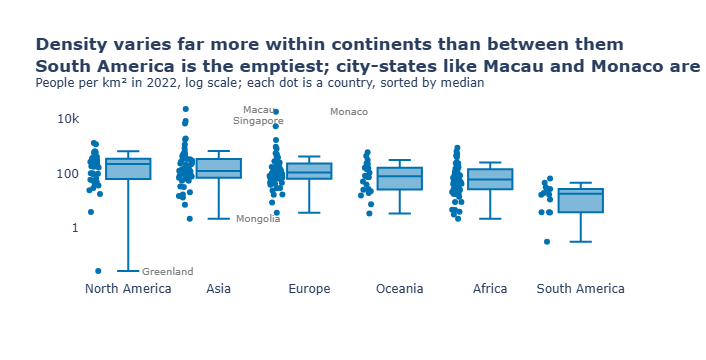

In [6]:
# Q4

order = df.groupby('Continent')['Density'].median().sort_values(ascending=False).index

fig = px.box(df, x='Continent', y='Density', points='all', log_y=True,
             hover_name='Country', category_orders={'Continent': list(order)},
             color_discrete_sequence=[BLUE], template='plotly_white',
             title='<b>Density varies far more within continents than between them<br>'
                   'South America is the emptiest; city-states like Macau and Monaco are the extremes</b>'
                   '<br><sup>People per km² in 2022, log scale; each dot is a country, sorted by median</sup>')
for name in ['Macau', 'Monaco', 'Singapore', 'Greenland', 'Mongolia']:
    r = df[df['Country'] == name].iloc[0]
    fig.add_annotation(x=r['Continent'], y=np.log10(r['Density']), text=name,   # log axis → log10
                       showarrow=False, xshift=40, font=dict(size=10, color='grey'))
fig.update_xaxes(title=None)
fig.update_yaxes(title=None, showgrid=False)
fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

**Choropleth Map.** As the question requires answering the “where in the world”, location is the data, and the map is the only way to present it. Growth and decline have an obvious zero point, hence the purple-orange diverging color scale centered on 0 (safe for CVD, no red/green). The color range is limited to ±50% so that the outliers such as Qatar with its 317% don’t swamp the rest.
**Finding:** 34 countries shrank, and more than half of them (18) are located in Europe, primarily Eastern Europe: Lithuania -24%, Moldova -23%, Ukraine, Latvia. The fastest growing countries were located in Africa and the Gulf region: Qatar 317%, UAE 188%, Niger 125%.

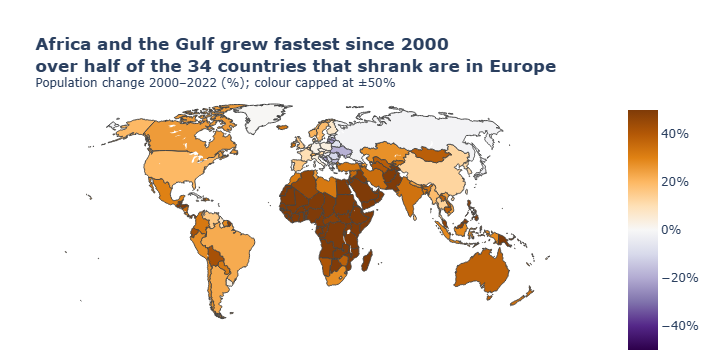

In [8]:
# Q5

df['Change 2000–22 (%)'] = (df['2022 Population'] / df['2000 Population'] - 1) * 100
n_shrink = (df['Change 2000–22 (%)'] < 0).sum()

fig = px.choropleth(df, locations='CCA3', locationmode='ISO-3',
                    color='Change 2000–22 (%)', hover_name='Country',
                    color_continuous_scale='PuOr_r', color_continuous_midpoint=0,
                    range_color=[-50, 50], template='plotly_white',
                    title=f'<b>Africa and the Gulf grew fastest since 2000<br>'
                          f'over half of the {n_shrink} countries that shrank are in Europe</b>'
                          '<br><sup>Population change 2000–2022 (%); colour capped at ±50%</sup>')
fig.update_geos(showframe=False, showcoastlines=False, projection_type='natural earth')
fig.update_layout(coloraxis_colorbar=dict(title=None, ticksuffix='%'), margin=dict(l=0, r=0, b=0))
fig.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

**Treemap.** It is a part-to-whole problem, which consists of two nested layers (continent → country). The treemap is able to display both the parts and the whole in the same graphic where the area is proportional to the population size. There is no way a pie chart or a stacked bar will fit 234 countries. Asia is marked with orange since it is the focus of the story while all other continents are in grey. 
**Finding:** nearly 59% of people live in Asia, and India and China together account for 36% of the global population.

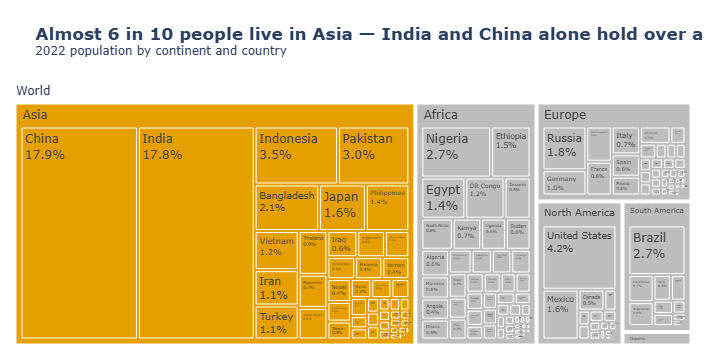

In [9]:
# Q6

fig = px.treemap(df, path=[px.Constant('World'), 'Continent', 'Country'],
                 values='2022 Population', color='Continent',
                 color_discrete_map={'(?)': 'white', 'Asia': ACCENT, 'Africa': GREY,
                                     'Europe': GREY, 'North America': GREY,
                                     'South America': GREY, 'Oceania': GREY},
                 template='plotly_white',
                 title='<b>Almost 6 in 10 people live in Asia — India and China alone hold over a third of humanity</b>'
                       '<br><sup>2022 population by continent and country</sup>')
fig.update_traces(texttemplate='%{label}<br>%{percentRoot:.1%}', root_color='white')
fig.update_layout(margin=dict(t=80, l=10, r=10, b=10))
fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

**Fully stacked bar chart in percentages (100%).** In the problem, we are asked about the percentage of 100%-total belonging to particular groups. The fully stacked bar chart maintains the total equal, i.e., what we will see is merely structural changes. Africa comes first, as it gives us the unified starting point to compare things. Two major groups considered in the problem get two accent colors (Africa - orange, Europe - blue), and Asia, as well as the rest of the world, is grey-colored. The labels are put right to the segments and beside the rightmost bar, which makes it unnecessary to have a legend here.
**Finding:** Africa grew its share from 10% to 18%, while Europe's decreased from 18% to 9%; their places swapped, basically. Asia remained about the same, as its share was only up from 58% to 59%, while the rest of the world took about 14%.

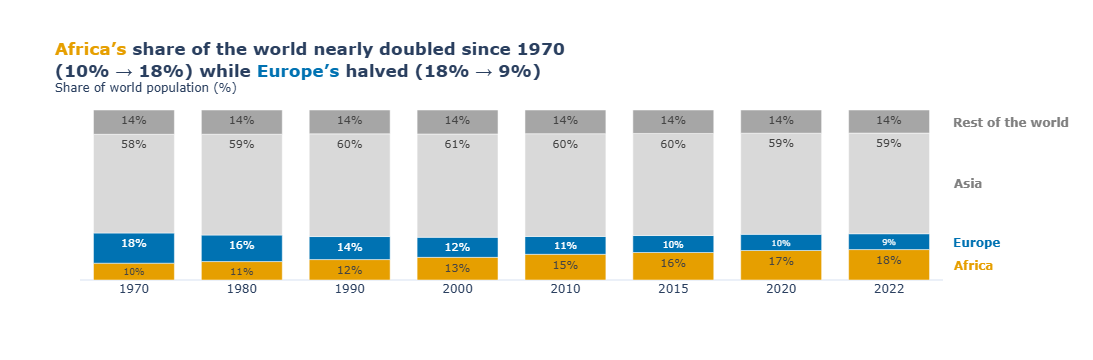

In [10]:
# Q7

df_long['Group'] = df_long['Continent'].where(
    df_long['Continent'].isin(['Africa', 'Asia', 'Europe']), 'Rest of the world')
share = df_long.groupby(['Year', 'Group'], as_index=False)['Population'].sum()
share['Share'] = share['Population'] / share.groupby('Year')['Population'].transform('sum') * 100
share['Year'] = share['Year'].astype(str)   # years as categories (1970…2022 aren't evenly spaced)

fig = px.bar(share, x='Year', y='Share', color='Group',
             category_orders={'Group': ['Africa', 'Europe', 'Asia', 'Rest of the world']},
             color_discrete_map={'Africa': ACCENT, 'Europe': BLUE,
                                 'Asia': '#D9D9D9', 'Rest of the world': '#A6A6A6'},
             text=share['Share'].round(0).astype(int).astype(str) + '%',
             template='plotly_white',
             title=f'<b><span style="color:{ACCENT}">Africa’s</span> share of the world nearly doubled since 1970<br>'
                   f'(10% → 18%) while <span style="color:{BLUE}">Europe’s</span> halved (18% → 9%)</b>'
                   '<br><sup>Share of world population (%)</sup>')
fig.update_traces(textposition='inside', textfont_size=11)
fig.update_xaxes(title=None, type='category')
fig.update_yaxes(title=None, showgrid=False, showticklabels=False, range=[0, 100])


y0 = 0
for g in ['Africa', 'Europe', 'Asia', 'Rest of the world']:
    v = share.query("Year == '2022' and Group == @g")['Share'].iloc[0]
    fig.add_annotation(xref='paper', x=1, y=y0 + v / 2, text=f'<b>{g}</b>', showarrow=False,
                       xanchor='left', xshift=8,
                       font=dict(color={'Africa': ACCENT, 'Europe': BLUE}.get(g, 'grey')))
    y0 += v
fig.update_layout(showlegend=False, bargap=0.25, margin=dict(r=150, t=110))
fig.show()